# DỰ ÁN: PHÂN TÍCH CHẤT LƯỢNG KHÔNG KHÍ HÀ NỘI

# Phần 2: Phân tích khám phá dữ liệu (EDA)

### Chất lượng không khí theo giờ, theo mùa và theo thời tiết

# I. Import thư viện và khai báo hằng số

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 13, "axes.titleweight": "bold"})

CSV_PATH = "Data/hanoi-aqi-weather-data.csv"  # file CSV tạo ra ở Part 1

# --- Mùa ---
SEASON_OF_MONTH = {2: "Xuân", 3: "Xuân", 4: "Xuân",
                   5: "Hạ", 6: "Hạ", 7: "Hạ",
                   8: "Thu", 9: "Thu", 10: "Thu",
                   11: "Đông", 12: "Đông", 1: "Đông"}
SEASON_ORDER = ["Xuân", "Hạ", "Thu", "Đông"]
SEASON_COLORS = dict(zip(SEASON_ORDER, ["#4c9f50", "#e0a526", "#b5651d", "#3b6fb6"]))

# --- Ngưỡng mức độ ô nhiễm (US EPA) ---
LEVEL_LABELS = ["Tốt", "Trung bình", "Không tốt (nhóm nhạy cảm)", "Có hại", "Rất có hại", "Nguy hại"]
LEVEL_COLORS = ["#2e9e4f", "#e6c619", "#f28c28", "#d6372b", "#8b3a9c", "#6b1f2b"]
PM25_BINS = [0, 12, 35.5, 55.5, 150.5, 250.5, np.inf]   # nửa khoảng [a, b)
AQI_BINS = [0, 50, 100, 150, 200, 300, 500]             # khoảng (a, b]

WEATHER = ["Pressure", "Temperature", "Wind Speed", "Accumulated Hours of Rain",
           "Precipitation", "Relative Humidity"]
WEATHER_VI = {"Pressure": "Áp suất", "Temperature": "Nhiệt độ", "Wind Speed": "Tốc độ gió",
              "Accumulated Hours of Rain": "Số giờ mưa liên tục", "Precipitation": "Lượng mưa",
              "Relative Humidity": "Độ ẩm"}

# II. Đọc và kiểm tra dữ liệu

In [2]:
df = pd.read_csv(CSV_PATH, parse_dates=["Local Time"], index_col="Local Time")

print("Kích thước:", df.shape)
print("Khoảng thời gian:", df.index.min(), "->", df.index.max())
print("Tổng số giá trị thiếu:", int(df.isna().sum().sum()))
print("Số dòng trùng thời điểm:", int(df.index.duplicated().sum()))
full_range = pd.date_range(df.index.min(), df.index.max(), freq="h")
print("Số giờ bị thiếu so với chuỗi đầy đủ:", len(full_range.difference(df.index)))

# Các cột hằng số (không mang thông tin phân tích)
const_cols = [c for c in df.columns if df[c].nunique() == 1]
print("Cột chỉ có 1 giá trị:", const_cols)
df.dtypes.to_frame("dtype").T

Kích thước: (8785, 18)
Khoảng thời gian: 2023-03-08 00:00:00 -> 2024-03-08 00:00:00
Tổng số giá trị thiếu: 0
Số dòng trùng thời điểm: 0
Số giờ bị thiếu so với chuỗi đầy đủ: 0
Cột chỉ có 1 giá trị: ['City', 'Country Code', 'Timezone']


,UTC Time,City,Country Code,Timezone,AQI,CO,NO2,O3,PM10,PM25,SO2,Clouds,Precipitation,Pressure,Relative Humidity,Temperature,UV Index,Wind Speed
dtype,object,object,object,object,int64,float64,float64,float64,float64,float64,float64,int64,float64,int64,int64,float64,float64,float64


In [3]:
df = df.drop(columns=["UTC Time", "City", "Country Code", "Timezone"])

# Cột phụ trợ để nhóm dữ liệu
df["Season"] = pd.Categorical(df.index.month.map(SEASON_OF_MONTH), SEASON_ORDER, ordered=True)
df["Hour"] = df.index.hour
df["Month"] = df.index.to_period("M")

# Biến mới: số giờ mưa LIÊN TỤC tính đến thời điểm hiện tại (0 nếu không mưa)
raining = (df["Precipitation"] > 0).astype(int)
streak_id = (raining != raining.shift()).cumsum()
df["Accumulated Hours of Rain"] = raining.groupby(streak_id).cumsum()

df.head()

,AQI,CO,NO2,O3,PM10,PM25,SO2,Clouds,Precipitation,Pressure,Relative Humidity,Temperature,UV Index,Wind Speed,Season,Hour,Month,Accumulated Hours of Rain
Local Time,,,,,,,,,,,,,,,,,,
2023-03-08 00:00:00,131,170.6,29.3,53.3,58.8,47.0,67.3,91,0.0,1016,86,21.2,0.0,2.00,Xuân,0,2023-03,0
2023-03-08 01:00:00,126,158.7,25.0,54.0,56.3,45.0,65.0,100,0.0,1016,89,21.1,0.0,2.00,Xuân,1,2023-03,0
2023-03-08 02:00:00,118,150.2,21.7,55.0,52.5,42.0,65.7,100,0.0,1016,90,20.9,0.0,1.66,Xuân,2,2023-03,0
2023-03-08 03:00:00,126,141.6,18.3,56.0,56.3,45.0,66.3,100,0.0,1016,91,20.7,0.0,1.33,Xuân,3,2023-03,0
2023-03-08 04:00:00,118,133.1,15.0,57.0,52.5,42.0,67.0,100,0.0,1015,92,20.5,0.0,1.00,Xuân,4,2023-03,0


**Các khái niệm ở bước chuẩn bị**

- **DatetimeIndex**: chỉ mục dạng thời gian, mỗi dòng gắn với một thời điểm. Nhờ đó có thể nhóm theo giờ, ngày, tháng (`groupby`), gộp theo ngày (`resample`) và tính trung bình trượt (`rolling`).
- **Giá trị thiếu**: ô không có dữ liệu. Nếu không xử lý, thống kê và mô hình sẽ sai hoặc báo lỗi.
- **Dòng trùng**: cùng một thời điểm xuất hiện nhiều lần, làm một giờ bị tính nhiều lần.
- **Giờ bị thiếu**: chuỗi theo giờ phải liên tục. Chuỗi bị đứt quãng làm sai trung bình trượt và các mô hình chuỗi thời gian ở Part 3.
- **Cột hằng**: cột chỉ có một giá trị duy nhất (ví dụ tên thành phố), không mang thông tin phân tích nên bỏ.
- **Biến phân loại có thứ tự (Categorical)**: biến dạng nhãn (Xuân, Hạ, Thu, Đông) có thứ tự cố định, để bảng và biểu đồ luôn xếp đúng thứ tự mùa.
- **Số giờ mưa liên tục**: biến mới đếm đã mưa liên tiếp bao nhiêu giờ (0 nếu không mưa). Ý nghĩa: mưa kéo dài có thể rửa bụi hiệu quả hơn mưa thoáng qua. Cách tính: gán mã cho từng chuỗi giờ mưa liên tiếp rồi đếm tích lũy trong mỗi chuỗi.

**Nhận xét**

- Dữ liệu gồm 8.785 dòng theo giờ, từ 08/03/2023 đến 08/03/2024.
- Không có giá trị thiếu, không có dòng trùng và không đứt quãng giờ nào, nên không cần nội suy hay loại bỏ dòng.
- Bỏ 4 cột: `City`, `Country Code`, `Timezone` (chỉ có một giá trị) và `UTC Time` (trùng thông tin với `Local Time`).

# III. Phân tích khám phá dữ liệu (EDA)

## 3.1. Thống kê mô tả

In [4]:
cols = ["AQI", "PM25", "PM10", "NO2", "O3", "SO2", "CO"] + [c for c in WEATHER if c != "Accumulated Hours of Rain"] + ["Clouds", "UV Index"]
df[cols].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]].round(2)

,mean,std,min,25%,50%,75%,max
AQI,117.63,53.38,21.0,78.00,104.0,151.0,500.00
PM25,49.40,47.70,1.0,24.67,36.0,55.0,446.00
PM10,62.31,57.24,1.3,31.30,46.3,70.0,604.00
NO2,27.91,34.06,2.0,11.00,16.7,28.0,378.00
O3,62.31,45.70,0.0,28.10,52.0,85.0,262.00
SO2,75.82,45.20,0.0,44.00,70.3,103.0,368.00
CO,436.15,985.53,9.0,124.70,169.0,269.2,15956.20
Pressure,1010.01,7.43,994.0,1004.00,1009.0,1016.0,1033.00
Temperature,25.28,5.65,8.6,21.60,26.1,29.2,40.00
Wind Speed,1.61,0.78,0.0,1.00,1.6,2.0,5.20


**Nhận xét**

- AQI trung bình 117,6 (trung vị 104) và PM2.5 trung bình 49,4 µg/m³ (trung vị 36,0), cao hơn nhiều so với khuyến nghị năm của WHO (5 µg/m³).
- PM2.5 có trung bình lớn hơn trung vị, độ lệch chuẩn gần bằng trung bình (47,7) và giá trị lớn nhất 446, cho thấy phân phối **lệch phải**: phần lớn thời gian ở mức vừa phải nhưng thỉnh thoảng có các đợt rất cao.
- Độ ẩm trung bình 78%, nhiệt độ trung bình 25,3°C, áp suất trung bình 1010 hPa: đúng với khí hậu nhiệt đới ẩm.

**Nhận xét**

- AQI trung bình 117,6 (trung vị 104) và PM2.5 trung bình 49,4 µg/m³ (trung vị 36,0), cao hơn nhiều so với khuyến nghị năm của WHO (5 µg/m³).
- PM2.5 có trung bình lớn hơn trung vị, độ lệch chuẩn gần bằng trung bình (47,7) và giá trị lớn nhất 446, cho thấy phân phối **lệch phải**: phần lớn thời gian ở mức vừa phải nhưng thỉnh thoảng có các đợt rất cao.
- Độ ẩm trung bình 78%, nhiệt độ trung bình 25,3°C, áp suất trung bình 1010 hPa: đúng với khí hậu nhiệt đới ẩm.

## 3.2. Chỉ số chất lượng không khí (AQI)

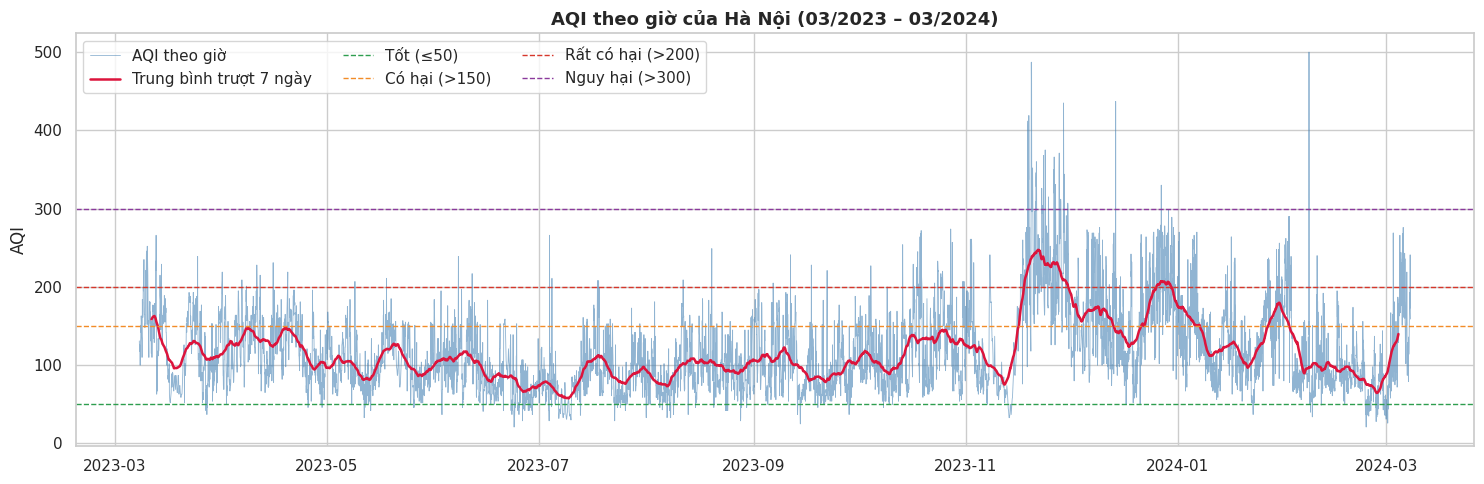

Thời điểm AQI cao nhất: 2024-02-07 19:00:00 | AQI = 500


In [5]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df.index, df["AQI"], color="steelblue", lw=0.6, alpha=0.6, label="AQI theo giờ")
ax.plot(df["AQI"].rolling(24 * 7, center=True).mean(), color="crimson", lw=1.8, label="Trung bình trượt 7 ngày")
for y, lab, c in [(50, "Tốt (≤50)", "#2e9e4f"), (150, "Có hại (>150)", "#f28c28"),
                  (200, "Rất có hại (>200)", "#d6372b"), (300, "Nguy hại (>300)", "#8b3a9c")]:
    ax.axhline(y, color=c, ls="--", lw=1, label=lab)
ax.set(title="AQI theo giờ của Hà Nội (03/2023 – 03/2024)", xlabel="", ylabel="AQI")
ax.legend(ncol=3, loc="upper left")
plt.tight_layout()
plt.show()

print("Thời điểm AQI cao nhất:", df["AQI"].idxmax(), "| AQI =", df["AQI"].max())

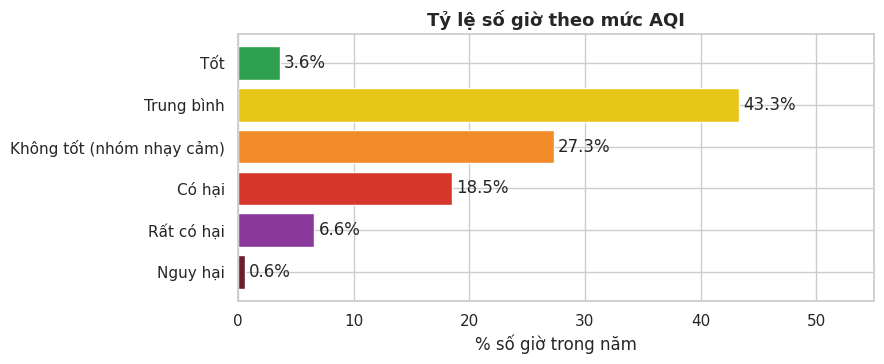

Tỷ lệ giờ có AQI > 150 (Có hại trở lên): 25.7%
Số giờ AQI > 300 theo tháng: {Period('2023-11', 'M'): 52, Period('2023-12', 'M'): 2, Period('2024-02', 'M'): 1}


In [6]:
aqi_level = pd.cut(df["AQI"], AQI_BINS, labels=LEVEL_LABELS)
share = aqi_level.value_counts(normalize=True).reindex(LEVEL_LABELS).mul(100).round(1)

fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.barh(LEVEL_LABELS[::-1], share.values[::-1], color=LEVEL_COLORS[::-1])
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set(title="Tỷ lệ số giờ theo mức AQI", xlabel="% số giờ trong năm", xlim=(0, 55))
plt.tight_layout()
plt.show()

print(f"Tỷ lệ giờ có AQI > 150 (Có hại trở lên): {(df['AQI'] > 150).mean() * 100:.1f}%")
haz = df[df["AQI"] > 300]
print("Số giờ AQI > 300 theo tháng:", haz.groupby("Month").size().to_dict())

### 3.2.1. Kiểm tra điểm bất thường (đột biến cô lập)

In [7]:
neighbor_median = df["PM25"].rolling(7, center=True).median()
spike_mask = (df["PM25"] > 100) & (df["PM25"] / neighbor_median > 4)
spikes = df.loc[spike_mask, ["AQI", "PM25", "PM10"]].assign(TrungVi_7h=neighbor_median[spike_mask].round(1))
display(spikes)

# Quanh điểm AQI = 500
t = df["AQI"].idxmax()
win = df.loc[t - pd.Timedelta(hours=6): t + pd.Timedelta(hours=6), ["AQI", "PM25", "PM10", "CO", "NO2", "SO2"]]
display(win)

# Chuỗi PM2.5 đã thay các đột biến cô lập bằng nội suy tuyến tính
df["PM25_clean"] = df["PM25"].mask(spike_mask).interpolate(limit_direction="both")
print(f"PM2.5 trung bình: gốc = {df['PM25'].mean():.2f} | đã xử lý đột biến = {df['PM25_clean'].mean():.2f}")

,AQI,PM25,PM10,TrungVi_7h
Local Time,,,,
2023-07-04 03:00:00,266,143.0,178.8,35.0
2023-07-04 19:00:00,211,101.0,126.3,23.0
2023-11-26 19:00:00,331,331.0,363.0,76.0
2024-02-07 19:00:00,500,417.0,604.0,49.7


,AQI,PM25,PM10,CO,NO2,SO2
Local Time,,,,,,
2024-02-07 13:00:00,79,25.60,39.3,4204.5,29.0,1.0
2024-02-07 14:00:00,136,48.86,59.4,1903.3,26.2,95.0
2024-02-07 15:00:00,98,34.11,49.0,1515.8,15.0,28.7
2024-02-07 16:00:00,94,32.30,52.4,1907.8,18.5,27.3
2024-02-07 17:00:00,97,33.80,52.2,1750.2,17.6,25.3
2024-02-07 18:00:00,79,25.40,48.6,3586.0,17.3,1.0
2024-02-07 19:00:00,500,417.00,604.0,403.0,46.0,74.0
2024-02-07 20:00:00,139,49.70,77.7,987.6,20.8,74.0
2024-02-07 21:00:00,156,59.67,74.7,2022.4,14.1,25.3


PM2.5 trung bình: gốc = 49.40 | đã xử lý đột biến = 49.32


**AQI (Air Quality Index)** là chỉ số quy đổi nồng độ các chất ô nhiễm về thang 0–500 để dễ hiểu: càng cao thì không khí càng xấu. Ngưỡng dùng trong notebook theo US EPA: Tốt (≤50), Trung bình (51–100), Không tốt cho nhóm nhạy cảm (101–150), Có hại (151–200), Rất có hại (201–300), Nguy hại (>300).

**Biểu đồ đường (line chart)** nối các giá trị theo thời gian, dùng để xem xu hướng và các đợt tăng giảm. Đường ngang đứt nét là các ngưỡng, giúp thấy chuỗi đang ở mức nào.

**Trung bình trượt 7 ngày (`rolling mean`)**: tại mỗi thời điểm, lấy trung bình của 7 ngày xung quanh. Mục đích là làm mượt nhiễu từng giờ để thấy xu hướng chung.

**Chia mức (`pd.cut`)**: gán mỗi giá trị vào nhóm theo các ngưỡng. Sau đó đếm tỷ lệ giờ ở từng nhóm và vẽ **biểu đồ cột ngang (bar chart)**, trong đó chiều dài cột là tỷ lệ phần trăm số giờ.

**Đột biến cô lập**: một giờ nhảy vọt so với các giờ xung quanh rồi quay về ngay. Ô nhiễm thật thường kéo dài vài giờ, nên đột biến kiểu này thường là nhiễu hoặc lỗi đo.

- **Trung vị trượt (`rolling median`)**: trung vị của 7 giờ quanh mỗi điểm, dùng làm mức "bình thường" tại chỗ vì không bị ảnh hưởng bởi chính điểm bất thường. Ý tưởng tương tự bộ lọc Hampel.
- **Quy tắc đánh dấu**: PM2.5 lớn hơn 100 và lớn hơn 4 lần trung vị lân cận.
- **Nội suy tuyến tính (`interpolate`)**: thay giá trị bị đánh dấu bằng giá trị nằm trên đường thẳng nối hai điểm kề nó.

**Nhận xét**

- Chỉ 3,6% số giờ có AQI ở mức "Tốt", 43,3% ở mức "Trung bình" và 25,7% từ mức "Có hại" trở lên.
- Các giờ "Nguy hại" (AQI > 300) hiếm (55 giờ, khoảng 0,6%) và tập trung gần như hoàn toàn vào tháng 11/2023 (52 giờ), tháng 12 có 2 giờ, tháng 2 có 1 giờ.
- Điểm AQI = 500 lúc 19h ngày 07/02/2024 là giá trị đơn lẻ: PM2.5 nhảy từ khoảng 25 lên 417 µg/m³ rồi về khoảng 50 chỉ sau một giờ, trong khi CO, NO2 và SO2 không tăng tương ứng. Nhiều khả năng đây là nhiễu hoặc lỗi đo, **không nên coi là "đỉnh ô nhiễm trong năm"**.
- Có 4 giờ bị đánh dấu là đột biến cô lập. Ảnh hưởng đến kết quả chung rất nhỏ (PM2.5 trung bình 49,40 so với 49,32 sau khi xử lý).

## 3.3. Nồng độ PM2.5

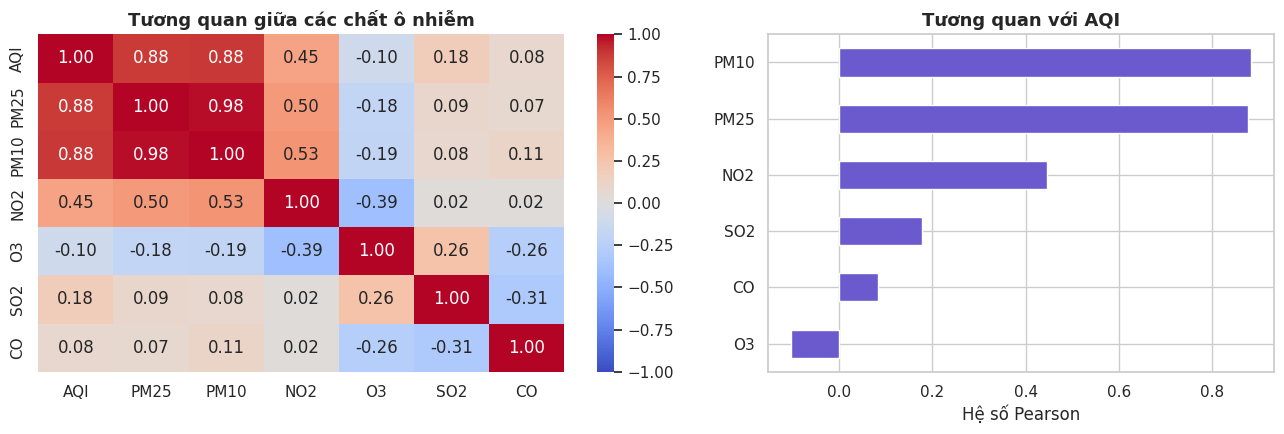

In [8]:
pollutants = ["AQI", "PM25", "PM10", "NO2", "O3", "SO2", "CO"]
corr_pol = df[pollutants].corr()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(corr_pol, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Tương quan giữa các chất ô nhiễm")
corr_pol["AQI"].drop("AQI").sort_values().plot(kind="barh", ax=ax[1], color="slateblue")
ax[1].set(title="Tương quan với AQI", xlabel="Hệ số Pearson")
plt.tight_layout()
plt.show()

**PM2.5** là bụi mịn có đường kính ≤ 2,5 micromet, đủ nhỏ để vào sâu trong phổi nên gây hại nhiều nhất, và là thành phần chính quyết định AQI.

**Hệ số tương quan Pearson (r)** đo mức độ hai biến cùng tăng hoặc cùng giảm theo dạng đường thẳng, nằm trong khoảng −1 đến +1:

- gần +1: cùng tăng; gần −1: một biến tăng thì biến kia giảm; gần 0: không có quan hệ tuyến tính.
- Quy ước thô: |r| < 0,3 là yếu, 0,3–0,7 là vừa, > 0,7 là mạnh.
- **Tương quan không phải nhân quả**: hai biến liên quan với nhau chưa chắc biến này gây ra biến kia.

**Heatmap (bản đồ nhiệt)** là bảng trong đó màu thể hiện giá trị. Ở đây mỗi ô là hệ số tương quan của một cặp biến: đỏ là dương, xanh là âm, càng đậm càng mạnh.

Ý nghĩa: giúp chọn PM2.5 làm biến phân tích chính vì có tương quan rất cao với AQI. PM2.5 và PM10 gần như trùng nhau nên PM10 không thêm nhiều thông tin độc lập.

**Nhận xét**

- PM2.5 và PM10 đều có tương quan 0,88 với AQI, và tương quan với nhau tới 0,98. Các chất còn lại yếu hơn nhiều: NO2 0,45, SO2 0,18, CO 0,08, O3 âm (−0,10).
- Do đó phân tích tập trung vào PM2.5. PM10 gần như trùng với PM2.5 nên không thêm nhiều thông tin độc lập.

### 3.3.1. Phân phối PM2.5 và tỷ lệ giờ theo mức ô nhiễm

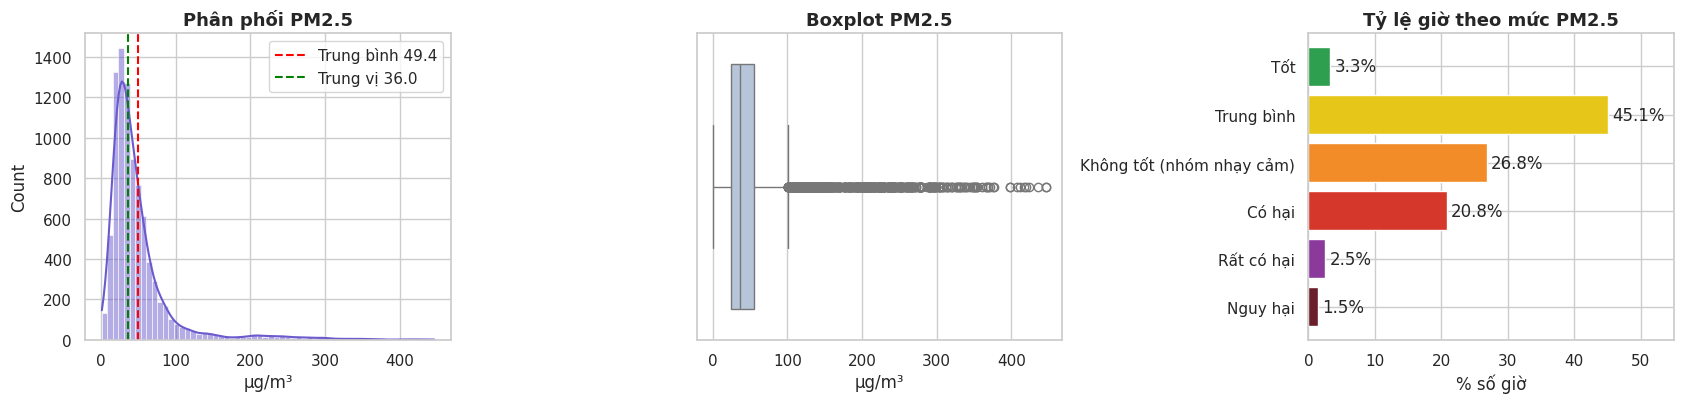

Độ lệch (skewness): 3.54
Ngưỡng outlier theo IQR: 100.5 µg/m³ -> 650 giờ vượt ngưỡng
Số giờ PM2.5 >= 250.5 (Nguy hại): 132


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))

sns.histplot(df["PM25"], bins=60, kde=True, color="slateblue", ax=ax[0])
ax[0].axvline(df["PM25"].mean(), color="red", ls="--", label=f"Trung bình {df['PM25'].mean():.1f}")
ax[0].axvline(df["PM25"].median(), color="green", ls="--", label=f"Trung vị {df['PM25'].median():.1f}")
ax[0].set(title="Phân phối PM2.5", xlabel="µg/m³")
ax[0].legend()

sns.boxplot(x=df["PM25"], color="lightsteelblue", ax=ax[1])
ax[1].set(title="Boxplot PM2.5", xlabel="µg/m³")

pm_level = pd.cut(df["PM25"], PM25_BINS, labels=LEVEL_LABELS, right=False)
pm_share = pm_level.value_counts(normalize=True).reindex(LEVEL_LABELS).mul(100)
bars = ax[2].barh(LEVEL_LABELS[::-1], pm_share.values[::-1], color=LEVEL_COLORS[::-1])
ax[2].bar_label(bars, fmt="%.1f%%", padding=3)
ax[2].set(title="Tỷ lệ giờ theo mức PM2.5", xlabel="% số giờ", xlim=(0, 55))

plt.tight_layout()
plt.show()

q1, q3 = df["PM25"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"Độ lệch (skewness): {df['PM25'].skew():.2f}")
print(f"Ngưỡng outlier theo IQR: {upper:.1f} µg/m³ -> {int((df['PM25'] > upper).sum())} giờ vượt ngưỡng")
print(f"Số giờ PM2.5 >= 250.5 (Nguy hại): {int((df['PM25'] >= 250.5).sum())}")

**Phân phối** cho biết dữ liệu tập trung ở đâu và trải rộng ra sao.

- **Histogram**: chia trục giá trị thành các khoảng (bin), cột cao thể hiện nhiều giờ rơi vào khoảng đó.
- **KDE (Kernel Density Estimate)**: đường cong mượt ước lượng hình dạng phân phối, vẽ chồng lên histogram.
- **Độ lệch (skewness)**: đo mức bất đối xứng. Dương: đuôi dài bên phải (nhiều giá trị thấp, ít giá trị rất cao). Gần 0: đối xứng.
- **Boxplot (biểu đồ hộp)**: hộp đi từ Q1 đến Q3 (chứa 50% dữ liệu ở giữa), vạch trong hộp là trung vị, "râu" kéo đến giá trị trong phạm vi 1,5×IQR, các chấm ngoài râu là **outlier**.
- **IQR = Q3 − Q1**. **Quy tắc IQR**: giá trị lớn hơn Q3 + 1,5×IQR được coi là outlier.

Lưu ý: outlier theo IQR chưa chắc là lỗi. Với PM2.5, nhiều outlier là các đợt ô nhiễm thật.

**Nhận xét**

- PM2.5 lệch phải rõ rệt (skewness 3,54): phần lớn giờ ở khoảng 25–55 µg/m³ nhưng có đuôi dài tới 446.
- Có 650 giờ vượt ngưỡng outlier theo IQR (100,5 µg/m³), trong đó 132 giờ ở mức "Nguy hại" (≥ 250,5). Những giờ này không phải lỗi dữ liệu mà chủ yếu là các đợt ô nhiễm thật, tập trung vào tháng 11/2023.
- Chỉ 3,3% số giờ ở mức "Tốt", còn 24,8% ở mức "Có hại" trở lên.

### 3.3.2. PM2.5 theo thời gian

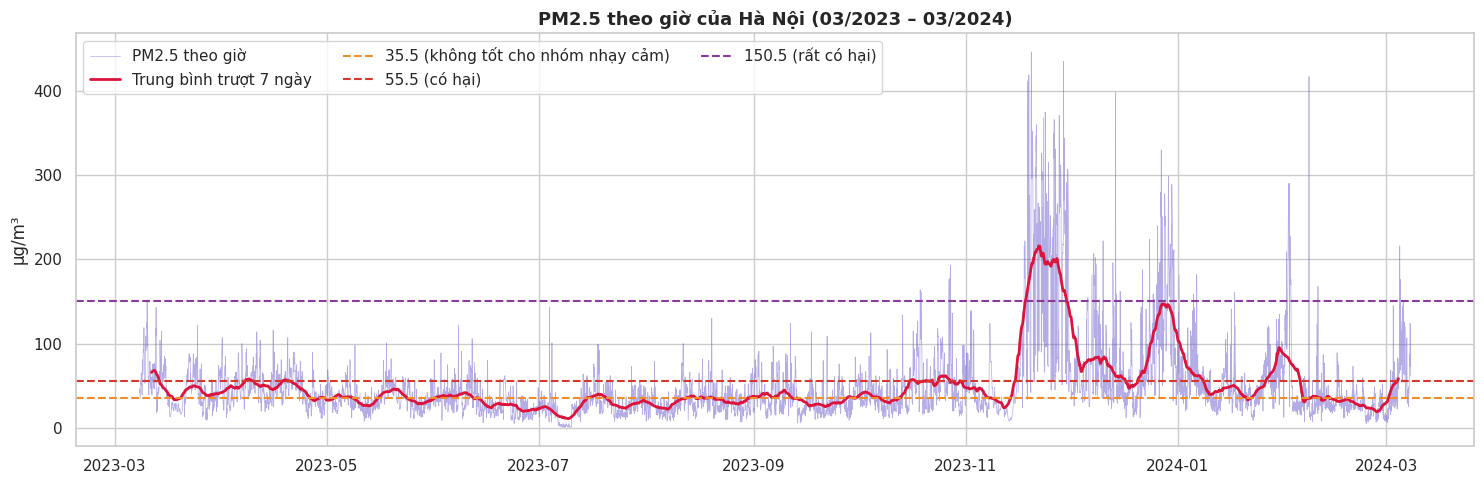

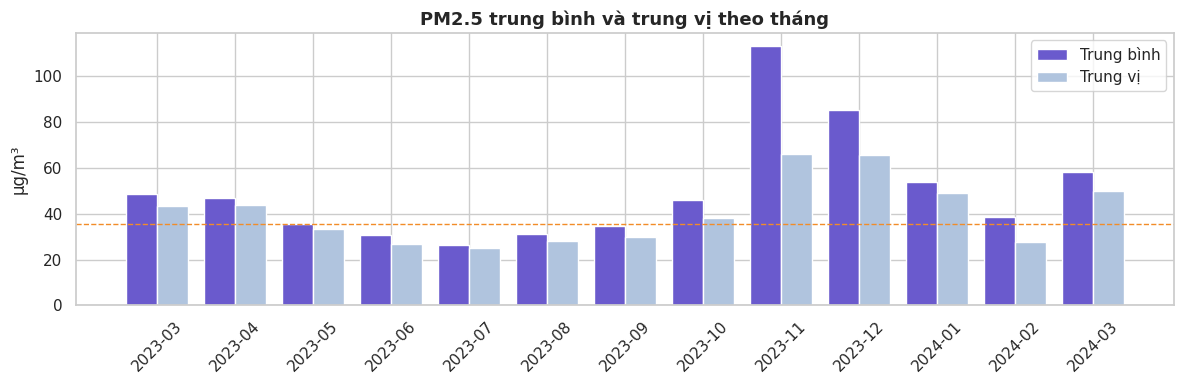

Month,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03
trung_binh,48.7,46.7,35.4,30.6,26.4,31.0,34.5,46.2,113.4,85.4,53.7,38.7,58.2
trung_vi,43.5,44.0,33.2,27.0,25.0,28.0,30.0,38.0,66.0,65.8,49.0,27.8,49.8
cao_nhat,152.0,116.0,101.0,122.0,143.0,130.0,124.0,193.0,446.0,398.0,182.0,417.0,216.0


In [10]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df.index, df["PM25"], color="slateblue", lw=0.5, alpha=0.5, label="PM2.5 theo giờ")
ax.plot(df["PM25"].rolling(24 * 7, center=True).mean(), color="crimson", lw=2, label="Trung bình trượt 7 ngày")
ax.axhline(35.5, color="#f28c28", ls="--", label="35.5 (không tốt cho nhóm nhạy cảm)")
ax.axhline(55.5, color="#d6372b", ls="--", label="55.5 (có hại)")
ax.axhline(150.5, color="#8b3a9c", ls="--", label="150.5 (rất có hại)")
ax.set(title="PM2.5 theo giờ của Hà Nội (03/2023 – 03/2024)", ylabel="µg/m³")
ax.legend(ncol=3, loc="upper left")
plt.tight_layout()
plt.show()

monthly = df.groupby("Month")["PM25"].agg(trung_binh="mean", trung_vi="median", cao_nhat="max").round(1)
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(monthly))
ax.bar(x - 0.2, monthly["trung_binh"], width=0.4, label="Trung bình", color="slateblue")
ax.bar(x + 0.2, monthly["trung_vi"], width=0.4, label="Trung vị", color="lightsteelblue")
ax.set_xticks(x, [str(p) for p in monthly.index], rotation=45)
ax.axhline(35.5, color="#f28c28", ls="--", lw=1)
ax.set(title="PM2.5 trung bình và trung vị theo tháng", ylabel="µg/m³")
ax.legend()
plt.tight_layout()
plt.show()
monthly.T

**Biểu đồ đường PM2.5 theo giờ** kèm **trung bình trượt 7 ngày** cho thấy xu hướng dài hạn (đường đỏ) và các đợt tăng giảm ngắn hạn (đường mờ). Các đường ngang đứt nét là ngưỡng mức độ ô nhiễm.

**Biểu đồ cột ghép theo tháng**: mỗi tháng có hai cột, trung bình và trung vị.

- Nếu **trung bình ≫ trung vị**: tháng đó có vài đợt rất cao kéo trung bình lên, không phải ngày nào cũng cao.
- Nếu hai giá trị gần nhau: mức ô nhiễm khá đều trong tháng.

**Nhận xét**

- PM2.5 thấp nhất vào mùa hè (tháng 7: trung bình 26,4 µg/m³), tăng dần từ tháng 10 và đạt đỉnh vào tháng 11/2023 (trung bình 113,4, tối đa 446), rồi giảm dần.
- Tháng 11 có trung bình (113,4) lớn hơn nhiều trung vị (66,0): tháng này có vài đợt rất nặng chứ không phải ngày nào cũng cao. Tháng 12/2023 cũng cao (trung bình 85,4).
- Tháng 3/2024 (58,2) chỉ gồm vài ngày đầu tháng nên chưa phản ánh cả tháng.

### 3.3.3. PM2.5 theo giờ trong ngày

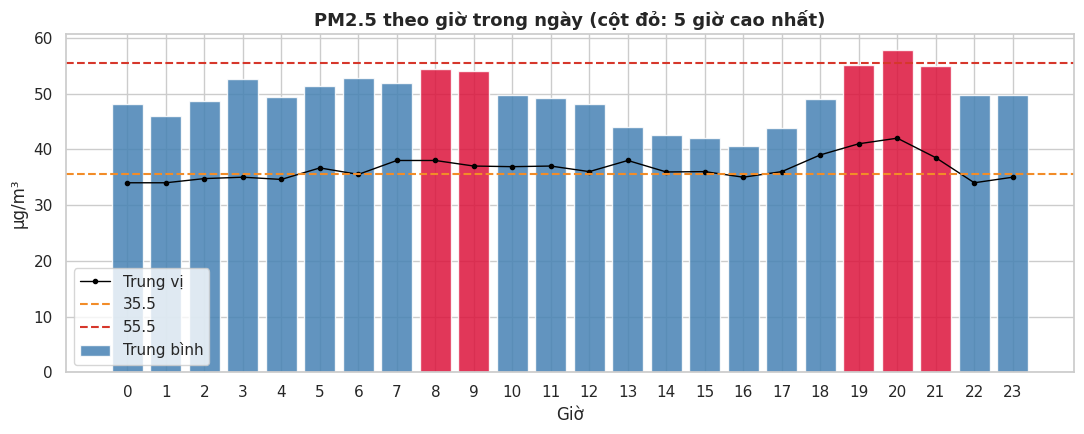

5 giờ có PM2.5 trung bình cao nhất:
Hour
20    57.75
19    55.19
21    54.89
8     54.40
9     54.09
Giờ thấp nhất: 16h (40.6 µg/m³)
Chênh lệch cao nhất - thấp nhất trong ngày: 17.1 µg/m³


In [11]:
hourly = df.groupby("Hour")["PM25"].agg(["mean", "median"])
top5 = hourly["mean"].nlargest(5)

fig, ax = plt.subplots(figsize=(11, 4.5))
colors = ["crimson" if h in top5.index else "steelblue" for h in hourly.index]
ax.bar(hourly.index, hourly["mean"], color=colors, alpha=0.85, label="Trung bình")
ax.plot(hourly.index, hourly["median"], color="black", marker="o", ms=3, lw=1, label="Trung vị")
ax.axhline(35.5, color="#f28c28", ls="--", label="35.5")
ax.axhline(55.5, color="#d6372b", ls="--", label="55.5")
ax.set(title="PM2.5 theo giờ trong ngày (cột đỏ: 5 giờ cao nhất)", xlabel="Giờ", ylabel="µg/m³")
ax.set_xticks(range(24))
ax.legend()
plt.tight_layout()
plt.show()

print("5 giờ có PM2.5 trung bình cao nhất:")
print(top5.round(2).to_string())
print(f"Giờ thấp nhất: {hourly['mean'].idxmin()}h ({hourly['mean'].min():.1f} µg/m³)")
print(f"Chênh lệch cao nhất - thấp nhất trong ngày: {hourly['mean'].max() - hourly['mean'].min():.1f} µg/m³")

**Nhóm theo giờ (`groupby("Hour")`)**: gom tất cả các giá trị cùng giờ trong năm (ví dụ mọi lúc 8h) rồi lấy trung bình. Kết quả là "hình dạng điển hình của một ngày".

**Biểu đồ cột theo giờ**: mỗi cột là PM2.5 trung bình của một giờ, đường đen là trung vị; 5 giờ cao nhất tô đỏ.

Ý nghĩa: cho biết khung giờ nào không khí xấu nhất, ví dụ trùng giờ cao điểm giao thông. Đây là **gợi ý**, không phải chứng minh nguyên nhân.

**Nhận xét**

- PM2.5 có hai đỉnh trong ngày: **19–21h tối** (cao nhất lúc 20h với 57,75 µg/m³) và **8–9h sáng** (khoảng 54). Hai khung giờ này trùng giờ cao điểm đi làm và tan tầm, nên giao thông là một giải thích hợp lý, nhưng dữ liệu chưa chứng minh điều đó.
- Thấp nhất vào buổi chiều, thấp nhất lúc 16h (40,6 µg/m³).
- Không giờ nào có trung bình dưới 35,5 µg/m³, tức giờ "sạch nhất" trong ngày vẫn ở mức không tốt cho nhóm nhạy cảm. Chênh lệch giữa giờ cao nhất và thấp nhất chỉ 17,1 µg/m³, nhỏ hơn nhiều so với chênh lệch giữa các mùa.

### 3.3.4. PM2.5 theo mùa

,trung_binh,trung_vi,do_lech_chuan,muc
Season,,,,
Xuân,45.59,38.0,31.61,Không tốt (nhóm nhạy cảm)
Hạ,30.81,28.0,15.93,Trung bình
Thu,37.27,32.0,22.09,Không tốt (nhóm nhạy cảm)
Đông,83.86,57.0,75.10,Có hại


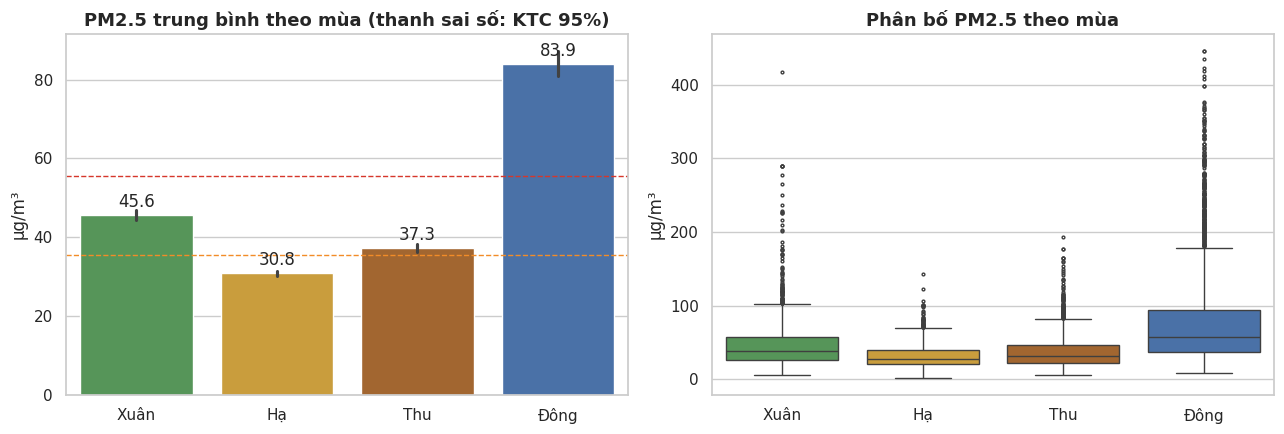

Kruskal-Wallis giữa 4 mùa: H = 1573.0, p = 0.00e+00
Mùa đông / mùa hạ (trung bình) = 2.72 lần


In [12]:
season_stats = df.groupby("Season", observed=True)["PM25"].agg(trung_binh="mean", trung_vi="median", do_lech_chuan="std").round(2)
season_stats["muc"] = pd.cut(season_stats["trung_binh"], PM25_BINS, labels=LEVEL_LABELS, right=False)
display(season_stats)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=df.reset_index(), x="Season", y="PM25", order=SEASON_ORDER, palette=SEASON_COLORS,
            errorbar=("ci", 95), ax=ax[0])
for cont in ax[0].containers:
    ax[0].bar_label(cont, fmt="%.1f", padding=3)
ax[0].axhline(35.5, color="#f28c28", ls="--", lw=1)
ax[0].axhline(55.5, color="#d6372b", ls="--", lw=1)
ax[0].set(title="PM2.5 trung bình theo mùa (thanh sai số: KTC 95%)", xlabel="", ylabel="µg/m³")
sns.boxplot(data=df.reset_index(), x="Season", y="PM25", order=SEASON_ORDER, palette=SEASON_COLORS,
            fliersize=2, ax=ax[1])
ax[1].set(title="Phân bố PM2.5 theo mùa", xlabel="", ylabel="µg/m³")
plt.tight_layout()
plt.show()

# Kiểm định Kruskal-Wallis: các mùa có phân bố PM2.5 khác nhau không?
groups = [g["PM25"].values for _, g in df.groupby("Season", observed=True)]
h, p = stats.kruskal(*groups)
print(f"Kruskal-Wallis giữa 4 mùa: H = {h:.1f}, p = {p:.2e}")
print(f"Mùa đông / mùa hạ (trung bình) = {season_stats.loc['Đông', 'trung_binh'] / season_stats.loc['Hạ', 'trung_binh']:.2f} lần")

**Cột trung bình theo mùa kèm khoảng tin cậy 95%**: thanh sai số cho biết khoảng mà trung bình thật nhiều khả năng nằm trong đó. Seaborn ước lượng bằng **bootstrap**: lấy mẫu lặp có hoàn lại nhiều lần từ chính dữ liệu và xem trung bình dao động thế nào. Hai mùa có thanh sai số không chồng nhau thì khác biệt có khả năng là thật.

**Kiểm định Kruskal–Wallis** kiểm tra xem các nhóm (4 mùa) có cùng một phân phối hay không.

- **Giả thuyết H0**: cả 4 mùa có cùng phân phối PM2.5.
- **Giá trị p (p-value)**: xác suất thu được khác biệt lớn như quan sát nếu H0 đúng. p nhỏ (thường < 0,05) nghĩa là khó cho rằng sự khác biệt chỉ do ngẫu nhiên.
- **Vì sao chọn kiểm định này**: là kiểm định **phi tham số** (dựa trên thứ hạng), không yêu cầu dữ liệu theo phân phối chuẩn. Phù hợp vì PM2.5 lệch phải.
- **Lưu ý**: dữ liệu theo giờ liên tiếp nhau tương quan mạnh nên giá trị p chỉ nên xem là bằng chứng tham khảo, không đọc quá chính xác.

**Nhận xét**

- Mùa Đông có PM2.5 trung bình 83,86 µg/m³, là mùa duy nhất ở mức "Có hại" và gấp khoảng 2,72 lần mùa Hạ (30,81). Mùa Xuân (45,59) và mùa Thu (37,27) ở mức "Không tốt cho nhóm nhạy cảm".
- Kiểm định Kruskal–Wallis cho p ≈ 0: sự khác biệt giữa các mùa là có thật, không phải do ngẫu nhiên. Vì dữ liệu theo giờ tương quan với nhau, giá trị p chỉ nên xem là bằng chứng định tính.
- Mùa Đông cũng biến động mạnh nhất (độ lệch chuẩn 75,1, lớn nhất trong 4 mùa) và trung bình (83,86) lớn hơn nhiều trung vị (57,0), do có các đợt ô nhiễm rất nặng.

### 3.3.5. Giờ × mùa

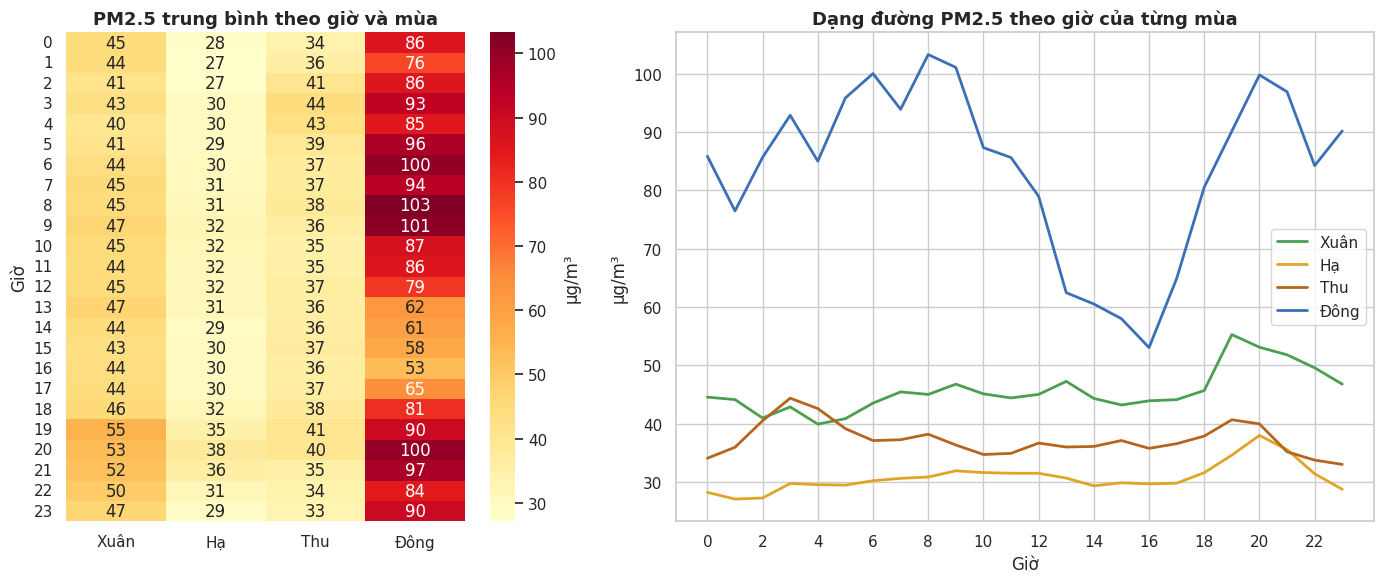

Chênh lệch giữa giờ cao nhất và giờ thấp nhất trong ngày theo mùa (µg/m³):
Season
Xuân    15.3
Hạ      10.9
Thu     11.4
Đông    50.2


In [13]:
heat = df.pivot_table(index="Hour", columns="Season", values="PM25", aggfunc="mean", observed=True)[SEASON_ORDER]

fig, ax = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.4]})
sns.heatmap(heat, cmap="YlOrRd", annot=True, fmt=".0f", cbar_kws={"label": "µg/m³"}, ax=ax[0])
ax[0].set(title="PM2.5 trung bình theo giờ và mùa", ylabel="Giờ", xlabel="")
for s in SEASON_ORDER:
    ax[1].plot(heat.index, heat[s], label=s, color=SEASON_COLORS[s], lw=2)
ax[1].set_xticks(range(0, 24, 2))
ax[1].set(title="Dạng đường PM2.5 theo giờ của từng mùa", xlabel="Giờ", ylabel="µg/m³")
ax[1].legend()
plt.tight_layout()
plt.show()

# Mức chênh đỉnh/đáy trong ngày ở từng mùa
swing = (heat.max() - heat.min()).round(1)
print("Chênh lệch giữa giờ cao nhất và giờ thấp nhất trong ngày theo mùa (µg/m³):")
print(swing.to_string())

**Bảng pivot (`pivot_table`)** là bảng tổng hợp hai chiều: hàng là giờ trong ngày, cột là mùa, mỗi ô là PM2.5 trung bình của giờ và mùa đó.

**Heatmap** tô màu bảng trên: ô càng đậm thì PM2.5 càng cao, dùng để tìm nhanh khung giờ và mùa xấu nhất. **Biểu đồ đường theo mùa** vẽ mỗi mùa một đường để so sánh hình dạng trong ngày giữa các mùa.

Ý nghĩa: cho thấy ảnh hưởng của giờ có giống nhau ở mọi mùa hay không (nếu các đường có hình dạng khác nhau thì giờ và mùa tác động lẫn nhau).

**Nhận xét**

- Mùa Đông cao hơn các mùa còn lại ở **mọi giờ** trong ngày, và có biên độ trong ngày lớn nhất (50,2 µg/m³: cao nhất lúc 8h với 103,3, thấp nhất lúc 16h với 53,1). Ba mùa còn lại chỉ dao động 10,9–15,3 µg/m³.
- Đỉnh buổi sáng (8–9h) chỉ thật sự rõ ở mùa Đông. Ở các mùa khác, đỉnh buổi tối (19–21h) nổi bật hơn: mùa Xuân cao nhất lúc 19h (55,3), mùa Hạ lúc 20h (38,0). Riêng mùa Thu cao nhất lúc 3h sáng (44,4).
- Như vậy hình "hai đỉnh sáng–tối" của đường trung bình cả năm chủ yếu do mùa Đông tạo ra. Giờ trong ngày chỉ có tác động đáng kể vào mùa Đông; các mùa còn lại gần như phẳng so với chênh lệch giữa các mùa.

### 3.3.6. Ngày thường và cuối tuần

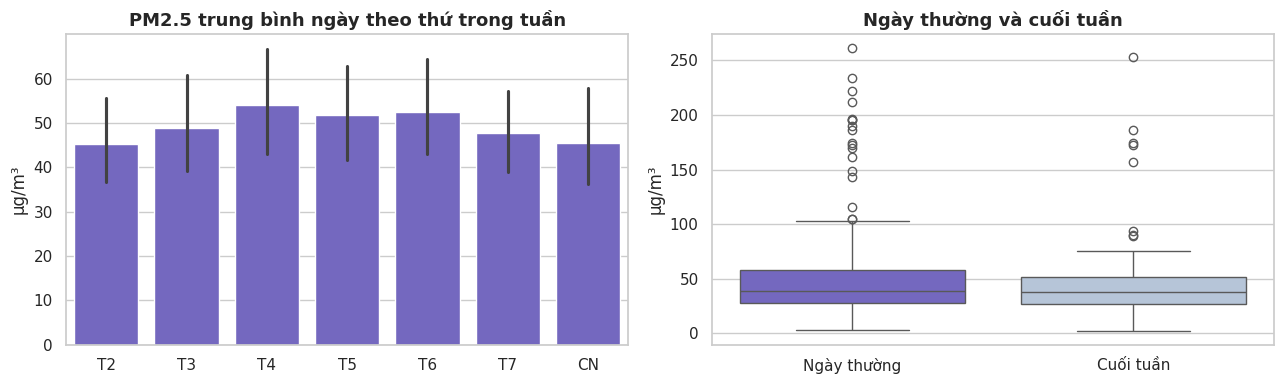

Trung bình: ngày thường = 50.5 | cuối tuần = 46.5 | trung vị: 38.8 vs 37.7
Mann-Whitney U (so sánh theo ngày): p = 0.459


In [14]:
daily_pm = df["PM25_clean"].resample("D").mean().to_frame("PM25")
daily_pm["Thu"] = daily_pm.index.dayofweek
daily_pm["Loai"] = np.where(daily_pm["Thu"] >= 5, "Cuối tuần", "Ngày thường")
day_names = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=daily_pm.reset_index(), x="Thu", y="PM25", color="slateblue", ax=ax[0])
ax[0].set_xticks(range(7), day_names)
ax[0].set(title="PM2.5 trung bình ngày theo thứ trong tuần", xlabel="", ylabel="µg/m³")
sns.boxplot(data=daily_pm, x="Loai", y="PM25", order=["Ngày thường", "Cuối tuần"], palette=["slateblue", "lightsteelblue"], ax=ax[1])
ax[1].set(title="Ngày thường và cuối tuần", xlabel="", ylabel="µg/m³")
plt.tight_layout()
plt.show()

wd = daily_pm.loc[daily_pm["Loai"] == "Ngày thường", "PM25"]
we = daily_pm.loc[daily_pm["Loai"] == "Cuối tuần", "PM25"]
u, p = stats.mannwhitneyu(wd, we)
print(f"Trung bình: ngày thường = {wd.mean():.1f} | cuối tuần = {we.mean():.1f} | trung vị: {wd.median():.1f} vs {we.median():.1f}")
print(f"Mann-Whitney U (so sánh theo ngày): p = {p:.3f}")

**Gộp theo ngày (`resample("D")`)**: gom các giờ trong cùng một ngày thành một giá trị trung bình. Mỗi ngày là một quan sát, nên so sánh theo ngày hợp lý hơn so sánh theo giờ.

**Kiểm định Mann–Whitney U** so sánh **hai nhóm** (ngày thường và cuối tuần).

- **H0**: hai nhóm có cùng phân phối.
- Là kiểm định phi tham số (dựa trên thứ hạng), tương tự Kruskal–Wallis nhưng cho 2 nhóm.
- **Cách đọc**: p lớn (> 0,05) nghĩa là chưa đủ bằng chứng nói hai nhóm khác nhau. Điều này **không chứng minh** hai nhóm giống nhau.

**Nhận xét**

- Ngày thường có PM2.5 trung bình 50,5 µg/m³, cuối tuần 46,5 µg/m³ (trung vị gần như bằng nhau: 38,8 và 37,7).
- Kiểm định Mann–Whitney U cho p = 0,459 > 0,05: chưa có bằng chứng về sự khác biệt giữa ngày thường và cuối tuần. Điều này không chứng minh hai nhóm giống nhau, chỉ là dữ liệu chưa đủ để nói chúng khác nhau.

## 3.4. Thời tiết theo mùa

,Tong_mua_mm,Ap_suat_hPa,Do_am_pct,Nhiet_do_C,Gio_m_s,PM25
Season,,,,,,
Xuân,238.75,1011.70,82.02,22.23,1.83,45.59
Hạ,935.00,1003.49,77.08,29.97,1.65,30.81
Thu,1099.00,1006.91,77.30,28.43,1.46,37.27
Đông,135.50,1017.96,75.85,20.44,1.49,83.86


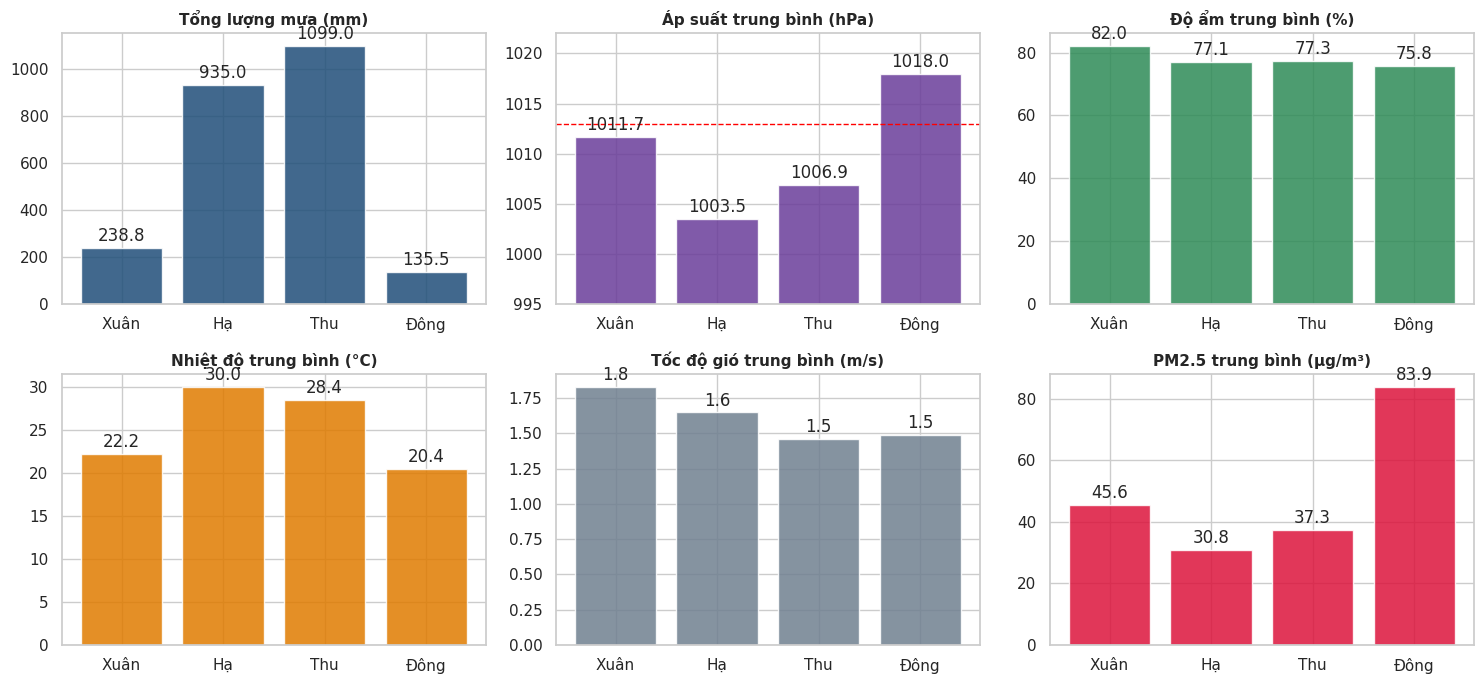

Tổng lượng mưa cả năm: 2408 mm | Tỷ lệ giờ có mưa: 19.7%


In [15]:
weather_season = df.groupby("Season", observed=True).agg(
    Tong_mua_mm=("Precipitation", "sum"),
    Ap_suat_hPa=("Pressure", "mean"),
    Do_am_pct=("Relative Humidity", "mean"),
    Nhiet_do_C=("Temperature", "mean"),
    Gio_m_s=("Wind Speed", "mean"),
    PM25=("PM25", "mean"),
).round(2).reindex(SEASON_ORDER)
display(weather_season)

specs = [("Tong_mua_mm", "Tổng lượng mưa (mm)", "#1f4e79"),
         ("Ap_suat_hPa", "Áp suất trung bình (hPa)", "#6a3d9a"),
         ("Do_am_pct", "Độ ẩm trung bình (%)", "#2e8b57"),
         ("Nhiet_do_C", "Nhiệt độ trung bình (°C)", "#e07b00"),
         ("Gio_m_s", "Tốc độ gió trung bình (m/s)", "#708090"),
         ("PM25", "PM2.5 trung bình (µg/m³)", "crimson")]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (col, title, color) in zip(axes.ravel(), specs):
    bars = ax.bar(SEASON_ORDER, weather_season[col], color=color, alpha=0.85)
    ax.bar_label(bars, fmt="%.1f", padding=2)
    ax.set_title(title, fontsize=11)
    if col == "Ap_suat_hPa":
        ax.set_ylim(995, 1022)
        ax.axhline(1013, color="red", ls="--", lw=1)
plt.tight_layout()
plt.show()

print(f"Tổng lượng mưa cả năm: {df['Precipitation'].sum():.0f} mm | Tỷ lệ giờ có mưa: {(df['Precipitation'] > 0).mean() * 100:.1f}%")

**Tổng hợp theo nhóm (`groupby().agg()`)**: nhóm dữ liệu theo mùa rồi tính mỗi biến một thống kê phù hợp (tổng cho lượng mưa, trung bình cho nhiệt độ, áp suất, độ ẩm, gió).

**Lưới biểu đồ cột (subplots)**: mỗi ô là một biến, cột là bốn mùa, con số ghi trên đầu cột. Với áp suất có thêm đường đứt nét 1013 hPa, là áp suất khí quyển chuẩn ở mực nước biển.

Ý nghĩa: cho thấy các yếu tố thời tiết thay đổi theo mùa như thế nào, để đọc đúng tương quan ở mục 3.5 (nhiều biến thời tiết thay đổi cùng nhau theo mùa).

**Nhận xét**

- **Mưa**: mùa Thu (1.099 mm) và mùa Hạ (935 mm) chiếm gần như toàn bộ lượng mưa cả năm (2.408 mm); mùa Đông khô nhất (135,5 mm). Chỉ 19,7% số giờ trong năm có mưa.
- **Áp suất**: cao nhất vào mùa Đông (1.018 hPa), thấp nhất vào mùa Hạ (1.003,5 hPa).
- **Nhiệt độ**: mùa Hạ (30,0°C) và mùa Thu (28,4°C) nóng hơn mùa Xuân (22,2°C) và mùa Đông (20,4°C). Độ ẩm (76–82%) và tốc độ gió (1,46–1,83 m/s) thay đổi ít giữa các mùa.
- Mùa Đông đồng thời là mùa lạnh nhất, áp cao nhất, ít mưa nhất và có PM2.5 cao nhất: các yếu tố thời tiết "đi cùng nhau" theo mùa, nên ở mục 3.5 cần kiểm tra tương quan trong từng mùa.

## 3.5. Tương quan giữa PM2.5 và thời tiết

,Pearson,Spearman
Áp suất,0.30,0.26
Độ ẩm,-0.01,-0.06
Lượng mưa,-0.09,-0.20
Số giờ mưa liên tục,-0.12,-0.20
Tốc độ gió,-0.16,-0.15
Nhiệt độ,-0.25,-0.25


PM2.5 trung bình khi không mưa = 53.1 | khi có mưa = 34.3 µg/m³


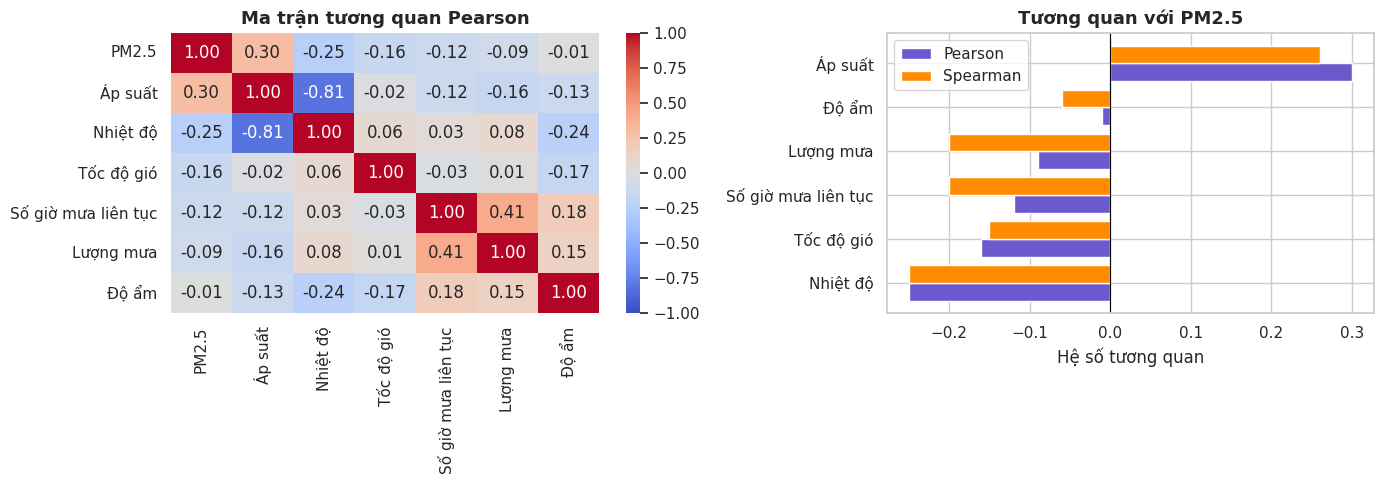

In [16]:
corr_df = df[["PM25"] + WEATHER]
pearson = corr_df.corr()["PM25"].drop("PM25")
spearman = corr_df.corr(method="spearman")["PM25"].drop("PM25")
tbl = pd.DataFrame({"Pearson": pearson, "Spearman": spearman}).round(2)
tbl.index = [WEATHER_VI[i] for i in tbl.index]
display(tbl.sort_values("Pearson", ascending=False))

rain_mean = df.groupby(df["Precipitation"] > 0)["PM25"].mean().round(1)
print(f"PM2.5 trung bình khi không mưa = {rain_mean[False]} | khi có mưa = {rain_mean[True]} µg/m³")

fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(corr_df.rename(columns=WEATHER_VI | {"PM25": "PM2.5"}).corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Ma trận tương quan Pearson")
plot_tbl = tbl.sort_values("Pearson")
y = np.arange(len(plot_tbl))
ax[1].barh(y - 0.2, plot_tbl["Pearson"], height=0.4, label="Pearson", color="slateblue")
ax[1].barh(y + 0.2, plot_tbl["Spearman"], height=0.4, label="Spearman", color="darkorange")
ax[1].set_yticks(y, plot_tbl.index)
ax[1].axvline(0, color="black", lw=0.8)
ax[1].set(title="Tương quan với PM2.5", xlabel="Hệ số tương quan")
ax[1].legend()
plt.tight_layout()
plt.show()

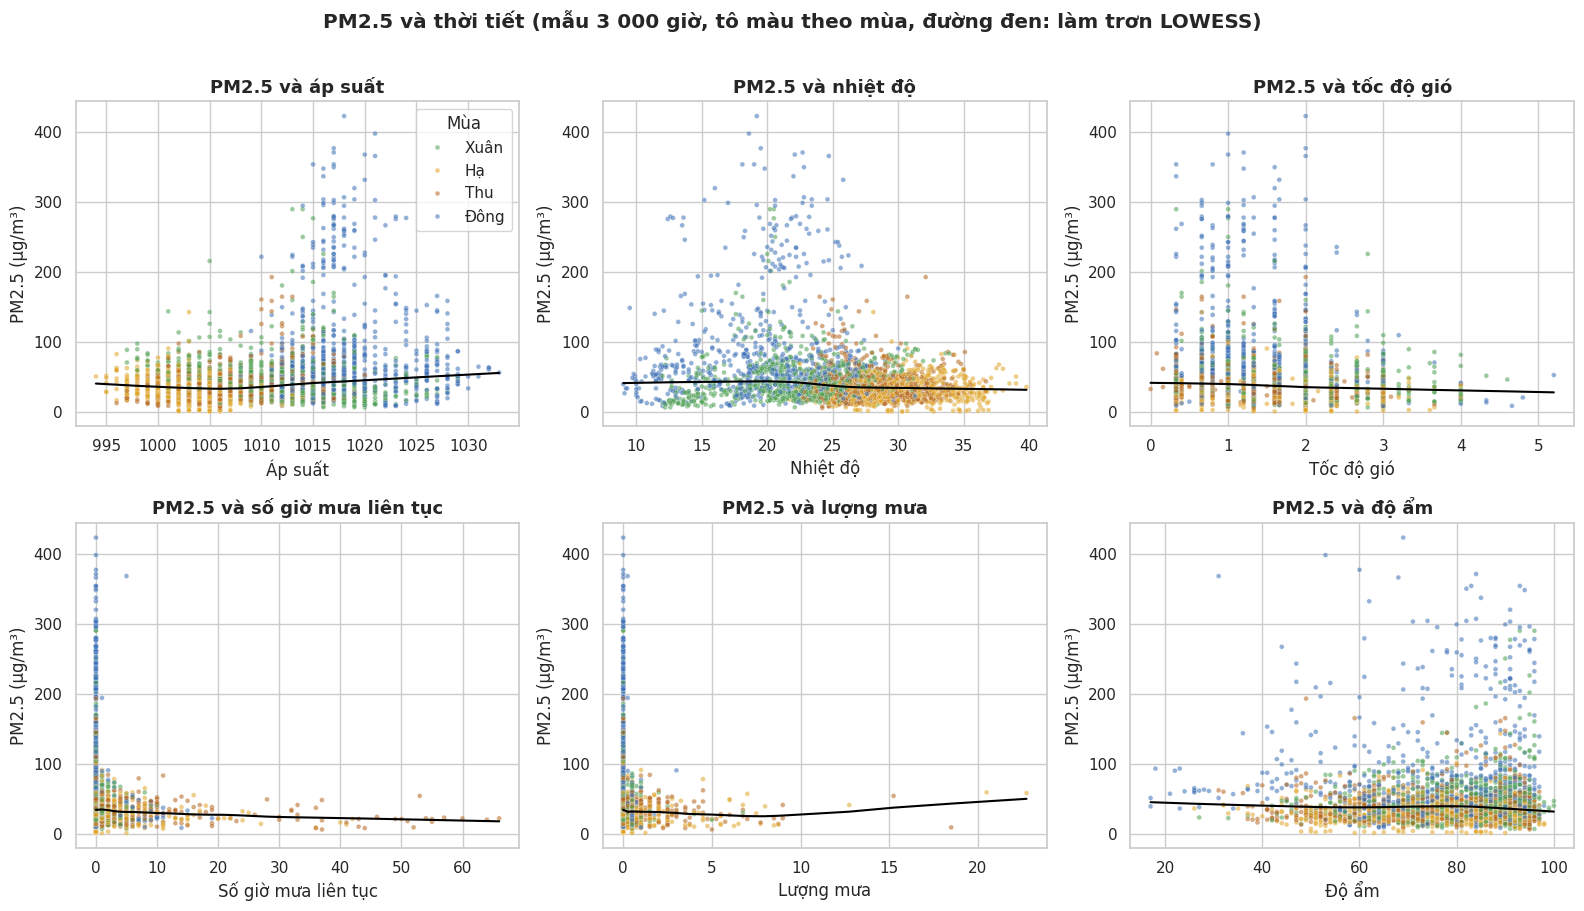

In [17]:
sample = df.sample(3000, random_state=42).reset_index().rename(columns={"Season": "Mùa"})
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), WEATHER):
    sns.scatterplot(data=sample, x=col, y="PM25", hue="Mùa", hue_order=SEASON_ORDER, palette=SEASON_COLORS,
                    s=12, alpha=0.55, ax=ax, legend=(col == "Pressure"))
    sns.regplot(data=sample, x=col, y="PM25", scatter=False, color="black", lowess=True, line_kws={"lw": 1.5}, ax=ax)
    ax.set(title=f"PM2.5 và {WEATHER_VI[col].lower()}", xlabel=WEATHER_VI[col], ylabel="PM2.5 (µg/m³)")
plt.suptitle("PM2.5 và thời tiết (mẫu 3 000 giờ, tô màu theo mùa, đường đen: làm trơn LOWESS)", y=1.01, fontweight="bold")
plt.tight_layout()
plt.show()

,Áp suất,Nhiệt độ,Tốc độ gió,Số giờ mưa liên tục,Lượng mưa,Độ ẩm
Cả năm,0.30,-0.25,-0.16,-0.12,-0.09,-0.01
Xuân,-0.18,0.15,-0.11,-0.02,-0.01,0.04
Hạ,-0.23,0.10,-0.05,-0.11,-0.02,-0.07
Thu,0.20,-0.02,-0.13,-0.18,-0.10,-0.06
Đông,0.04,-0.04,-0.24,-0.16,-0.16,0.05


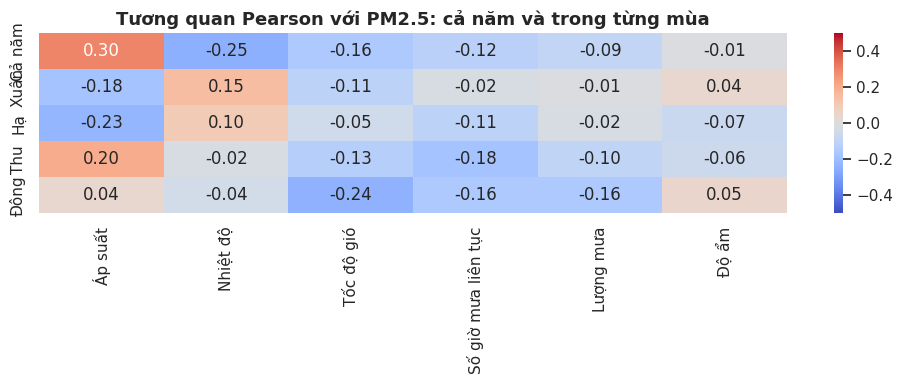

In [18]:
within = (df.groupby("Season", observed=True)[["PM25"] + WEATHER].corr()
            .xs("PM25", level=1)[WEATHER].reindex(SEASON_ORDER)
            .rename(columns=WEATHER_VI))
overall = pearson.rename(index=WEATHER_VI).to_frame("Cả năm").T
combined = pd.concat([overall, within]).round(2)
display(combined)

plt.figure(figsize=(10, 4))
sns.heatmap(combined, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-0.5, vmax=0.5)
plt.title("Tương quan Pearson với PM2.5: cả năm và trong từng mùa")
plt.tight_layout()
plt.show()

**Pearson và Spearman**

- **Pearson**: đo quan hệ *tuyến tính* giữa giá trị của hai biến; nhạy với giá trị cực đoan.
- **Spearman**: tính tương quan trên *thứ hạng* của giá trị, nên nắm bắt được quan hệ đơn điệu không tuyến tính (cùng chiều nhưng không thẳng) và ít bị ảnh hưởng bởi outlier. Hữu ích với lượng mưa, vì phần lớn giờ bằng 0 còn vài giờ rất lớn.
- Nếu hai hệ số khác nhau nhiều thì quan hệ không phải đường thẳng hoặc có nhiều giá trị cực đoan.

**Biểu đồ phân tán (scatter plot)**: mỗi chấm là một giờ, trục x là biến thời tiết, trục y là PM2.5. Tô màu theo mùa để thấy các mùa tạo thành cụm riêng. Vẽ mẫu ngẫu nhiên 3.000 giờ (không phải toàn bộ) để hình không bị dày đặc.

**LOWESS** (đường đen) là đường xu hướng cục bộ: tại mỗi điểm, nó làm trơn bằng cách hồi quy trên các điểm lân cận. Không giả định dữ liệu theo đường thẳng nên bắt được xu hướng cong.

**Biến nhiễu (confounder)**: một yếu tố, ở đây là *mùa*, tác động đồng thời lên cả hai biến nên tạo tương quan giả hoặc phóng đại tương quan thật. Mùa đông vừa lạnh, áp cao, ít mưa vừa ô nhiễm nên khi gộp cả năm, tương quan có thể chủ yếu là hiệu ứng mùa.

**Tương quan trong từng mùa (`groupby().corr()`)**: tính lại tương quan riêng cho từng mùa để loại hiệu ứng mùa. Nếu tương quan gần như biến mất hoặc đổi dấu khi tách mùa, nghĩa là tương quan gộp phản ánh mùa nhiều hơn là tác động riêng của biến thời tiết đó.

**Nhận xét**

- Tương quan gộp cả năm đều ở mức yếu đến vừa phải (|r| ≤ 0,30): áp suất +0,30, nhiệt độ −0,25, gió −0,16, số giờ mưa liên tục −0,12, lượng mưa −0,09, độ ẩm −0,01. Không có yếu tố thời tiết đơn lẻ nào giải thích được phần lớn biến động PM2.5.
- Với mưa, Spearman (−0,20) mạnh hơn Pearson (−0,09) vì lượng mưa phần lớn bằng 0. Trong giờ có mưa, PM2.5 trung bình thấp hơn rõ (34,3 so với 53,1 µg/m³ khi không mưa).
- Khi tách riêng từng mùa, tương quan của **áp suất** gần như biến mất ở mùa Đông (+0,04) và đổi dấu ở mùa Xuân, Hạ (−0,18, −0,23); **nhiệt độ** cũng gần 0 ở mùa Thu và mùa Đông. Con số +0,30 và −0,25 khi gộp cả năm chủ yếu phản ánh hiệu ứng mùa, không phải tác động riêng của từng yếu tố.
- **Gió** và **số giờ mưa liên tục** ổn định hơn: tương quan âm ở cả bốn mùa (gió mạnh nhất vào mùa Đông: −0,24), phù hợp với việc gió và mưa giúp phát tán và rửa bụi, nhưng mức độ vẫn yếu.
- Kết luận thận trọng: trong dữ liệu này, **mùa giải thích PM2.5 mạnh hơn bất kỳ biến thời tiết đơn lẻ nào**. Muốn tách vai trò riêng của từng biến cần mô hình đa biến, nằm ngoài phạm vi EDA.

**Tổng kết EDA**

- Chất lượng không khí Hà Nội kém quanh năm: PM2.5 trung bình 49,4 µg/m³, 24,8% số giờ từ mức "Có hại" trở lên; các đợt nặng nhất tập trung vào tháng 11/2023.
- Theo giờ: hai đỉnh vào 8–9h và 19–21h, thấp nhất buổi chiều; tuy nhiên đỉnh sáng chủ yếu đến từ mùa Đông.
- Theo mùa: mùa Đông tệ nhất (83,86 µg/m³), gấp khoảng 2,72 lần mùa Hạ; khác biệt giữa các mùa lớn hơn nhiều so với khác biệt giữa các giờ trong ngày.
- Thời tiết chỉ liên quan yếu đến vừa với PM2.5, và phần lớn tương quan gộp đến từ hiệu ứng mùa; gió và mưa là hai yếu tố còn ổn định khi tách mùa.
- Hạn chế: chỉ có 1 năm dữ liệu từ 1 điểm đo; tương quan không phải nhân quả; có 4 giờ nghi là nhiễu (trong đó điểm AQI = 500).